In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn import metrics
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

import os
os.chdir("/Users/lleid/Downloads")
#"C:\Users\lleid\Downloads\diabetes.csv"

In [7]:
col_names = ["pregnant","glucose","bp","skin","insulin","bmi","pedigre","age","label"]
pima = pd.read_csv("diabetes.csv", header=None, names = col_names)
df = pima.iloc[1:]
df

,pregnant,glucose,bp,skin,insulin,bmi,pedigre,age,label
1,6,148,72,35,0,33.6,0.627,50,1
2,1,85,66,29,0,26.6,0.351,31,0
3,8,183,64,0,0,23.3,0.672,32,1
4,1,89,66,23,94,28.1,0.167,21,0
5,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
764,10,101,76,48,180,32.9,0.171,63,0
765,2,122,70,27,0,36.8,0.34,27,0
766,5,121,72,23,112,26.2,0.245,30,0
767,1,126,60,0,0,30.1,0.349,47,1


In [10]:
# Selección de las características
feature_cols = ["pregnant","insulin","bmi","age","glucose","bp","pedigre"]
X = df[feature_cols]
y = df.label

In [11]:
#Creacion de las bases de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 1)

In [12]:
# sag: Stochastic Average Gradient
#newton-cg: Newton
#liblinear: Library for large linear classification (Algoritmo Coordiante Descent)
#lbfgs: Limited-memory Broyden-Fletcher-Goldfarb-Shanno Algorithm

# Regresión logística con Solucionador (Solver): sag

In [13]:
model = LogisticRegression(solver="sag")
clf = model.fit(X_train, y_train)

In [14]:
#Predicción de etiquetas de clase sobre datos de prueba
y_pred = model.predict(X_test)

#Impresión de coeficientes de la regresion de puntajes
print("Intercepto (Beta0)", clf.intercept_)
print("Pesos de cada variable (Beta1, Beta2, ..., Beta7)", clf.coef_)

Intercepto (Beta0) [-0.0118988]
Pesos de cada variable (Beta1, Beta2, ..., Beta7) [[ 0.0520938   0.00116432 -0.00937688 -0.00231901  0.01407828 -0.03084345
   0.00099502]]


In [15]:
# Evaluacion de la prediccion del modelo
score = model.score(X_test, y_test)
print("Score de precision:", score)

Score de precision: 0.6428571428571429


In [19]:
#Reporte de clasificacion 
print(classification_report(y_test, y_pred)) 
#en este caso no fue muy bueno porque tenemos porque tiene score f1 de 0.29

              precision    recall  f1-score   support

           0       0.67      0.89      0.76        99
           1       0.50      0.20      0.29        55

    accuracy                           0.64       154
   macro avg       0.58      0.54      0.52       154
weighted avg       0.61      0.64      0.59       154



# Regresión logística con Solucionador (Solver): Newton-cg

In [24]:
model = LogisticRegression(solver="newton-cg")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("----------------------------------------------------------------------")
score = model.score(X_test, y_test)
print("precisión global:", score)
print("----------------------------------------------------------------------")
print(classification_report(y_test, y_pred)) #accuracy(precision global) del 77% es mejor

Intercepto (Beta0):  [-8.0901646]
Pesos (Betas): [[ 0.12708994 -0.00095867  0.08544587  0.01165706  0.03653173 -0.01510538
   0.63048471]]
----------------------------------------------------------------------
precisión global: 0.7727272727272727
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.78      0.90      0.84        99
           1       0.75      0.55      0.63        55

    accuracy                           0.77       154
   macro avg       0.77      0.72      0.73       154
weighted avg       0.77      0.77      0.76       154



# Regresión logística con Solucionador (Solver): liblinear

In [25]:
model = LogisticRegression(solver="liblinear")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("----------------------------------------------------------------------")
score = model.score(X_test, y_test)
print("precisión global:", score)
print("----------------------------------------------------------------------")
print(classification_report(y_test, y_pred)) #accuracy(precision global) del 77% es mejor

Intercepto (Beta0):  [-5.37993555]
Pesos (Betas): [[ 1.18842180e-01 -3.17153980e-04  5.28246540e-02  3.80487479e-03
   2.87924885e-02 -1.90994375e-02  4.74843055e-01]]
----------------------------------------------------------------------
precisión global: 0.7662337662337663
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.77      0.90      0.83        99
           1       0.74      0.53      0.62        55

    accuracy                           0.77       154
   macro avg       0.76      0.71      0.72       154
weighted avg       0.76      0.77      0.76       154



# Regresión logística con Solucionador (Solver): saga

In [26]:
model = LogisticRegression(solver="saga")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("----------------------------------------------------------------------")
score = model.score(X_test, y_test)
print("precisión global:", score)
print("----------------------------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0):  [-0.00610383]
Pesos (Betas): [[ 0.03010093  0.00115536 -0.00950647  0.00095341  0.01389053 -0.03082615
   0.00048825]]
----------------------------------------------------------------------
precisión global: 0.6493506493506493
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.67      0.89      0.77        99
           1       0.52      0.22      0.31        55

    accuracy                           0.65       154
   macro avg       0.60      0.55      0.54       154
weighted avg       0.62      0.65      0.60       154



# Regresión logística con Solucionador (Solver): lbfgs

In [27]:
model = LogisticRegression(solver="lbfgs")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("----------------------------------------------------------------------")
score = model.score(X_test, y_test)
print("precisión global:", score)
print("----------------------------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0):  [-8.10385279]
Pesos (Betas): [[ 0.12715729 -0.00096267  0.08559412  0.011682    0.03657088 -0.01508649
   0.63352797]]
----------------------------------------------------------------------
precisión global: 0.7727272727272727
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.78      0.90      0.84        99
           1       0.75      0.55      0.63        55

    accuracy                           0.77       154
   macro avg       0.77      0.72      0.73       154
weighted avg       0.77      0.77      0.76       154



In [30]:
# Predicción de probabilidades para casos particulares
y_pred_probs = clf.predict_proba(X_test)[:,1]
y_pred_probs[0:5] #probabilidades de que estas personas sean diabeticos en este caso ninguna porque esta por debajo de 0.5

array([0.43650668, 0.31967398, 0.15787843, 0.04340139, 0.19968352])

In [31]:
y_test[0:5] #comparamos con los reales y si coincide

286    0
102    0
582    0
353    0
727    0
Name: label, dtype: str

In [34]:
#convertimos la base en un array para poder usar la libreria
y_test = y_test.to_numpy()
y_test[0:5]

array(['0', '0', '0', '0', '0'], dtype=object)

In [36]:
y_test = [int(numeric_string) for numeric_string in y_test]
y_test[0:5]

[0, 0, 0, 0, 0]

In [37]:
import numpy as np
y_pred_probs = np.round(y_pred_probs,0)
y_pred_probs[0:5]

array([0., 0., 0., 0., 0.])

In [38]:
# Graficación de la curva ROC y cálculo del área bajo ella
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
# fpr = false positive rate
# tpr = true positive rate
# thresholds = limites para valores de p
fpr, tpr, thresholds = roc_curve(y_test, y_pred_probs)
auc = roc_auc_score(y_test, y_pred_probs)

Text(0.5, 1.0, 'Curve ROC para Regresión Logística')

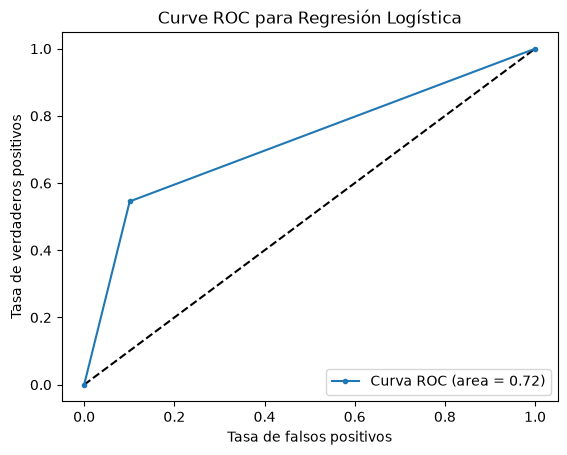

In [42]:
plt.plot([0,1], [0,1], 'k--')
plt.plot(fpr, tpr, marker=".", label="Curva ROC (area = %0.2f)" % auc)
plt.xlabel("Tasa de falsos positivos") #Fakse positive rate
plt.ylabel("Tasa de verdaderos positivos") #True positive rate
plt.legend(loc = "lower right")
plt.title("Curve ROC para Regresión Logística")